# 01. Spanish Market Structure and BME Competition Restrictions
**Project:** Quantitative Trading Framework — BME Stock Market Contest 2026  
**Objective:** Analyze the market microstructure of the Spanish continuous market (IBEX 35), identify structural liquidity constraints, and mathematically model tournament frictions (minimum €7 brokerage fee and asymmetric BME scoring function).


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from matplotlib.ticker import FuncFormatter

# BME Institutional Style Parameters
bme_purple = '#3d1696'
bme_green = '#6bb030'
text_gray = '#666666'
grid_gray = '#f0f0f0'

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,
    'axes.spines.bottom': True,
    'axes.edgecolor': grid_gray,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': grid_gray,
    'grid.linestyle': '--',
    'grid.linewidth': 1.0,
    'xtick.color': text_gray,
    'ytick.color': text_gray,
    'xtick.bottom': False,
    'ytick.left': False,
    'font.family': 'sans-serif',
    'text.color': '#333333',
    'axes.labelcolor': text_gray,
    'axes.prop_cycle': cycler('color', [bme_purple, bme_green, '#FF9F1C', '#E71D36']),
    'legend.frameon': False,
    'legend.loc': 'upper right',
    'legend.fontsize': 10
})

print("Analysis environment and BME institutional style initialized successfully.")


Analysis environment and BME institutional style initialized successfully.


## 1. Macro Regime and Historical Dynamics of the IBEX 35
Before dissecting individual constituents and tournament friction rules, we analyze the long-term structural behavior of the benchmark index. Unlike secular growth indices dominated by mega-cap technology (e.g., S&P 500), the Spanish IBEX 35 has historically operated as a cyclical, range-bound market characterized by elevated baseline volatility and recurring sovereign and banking shocks.


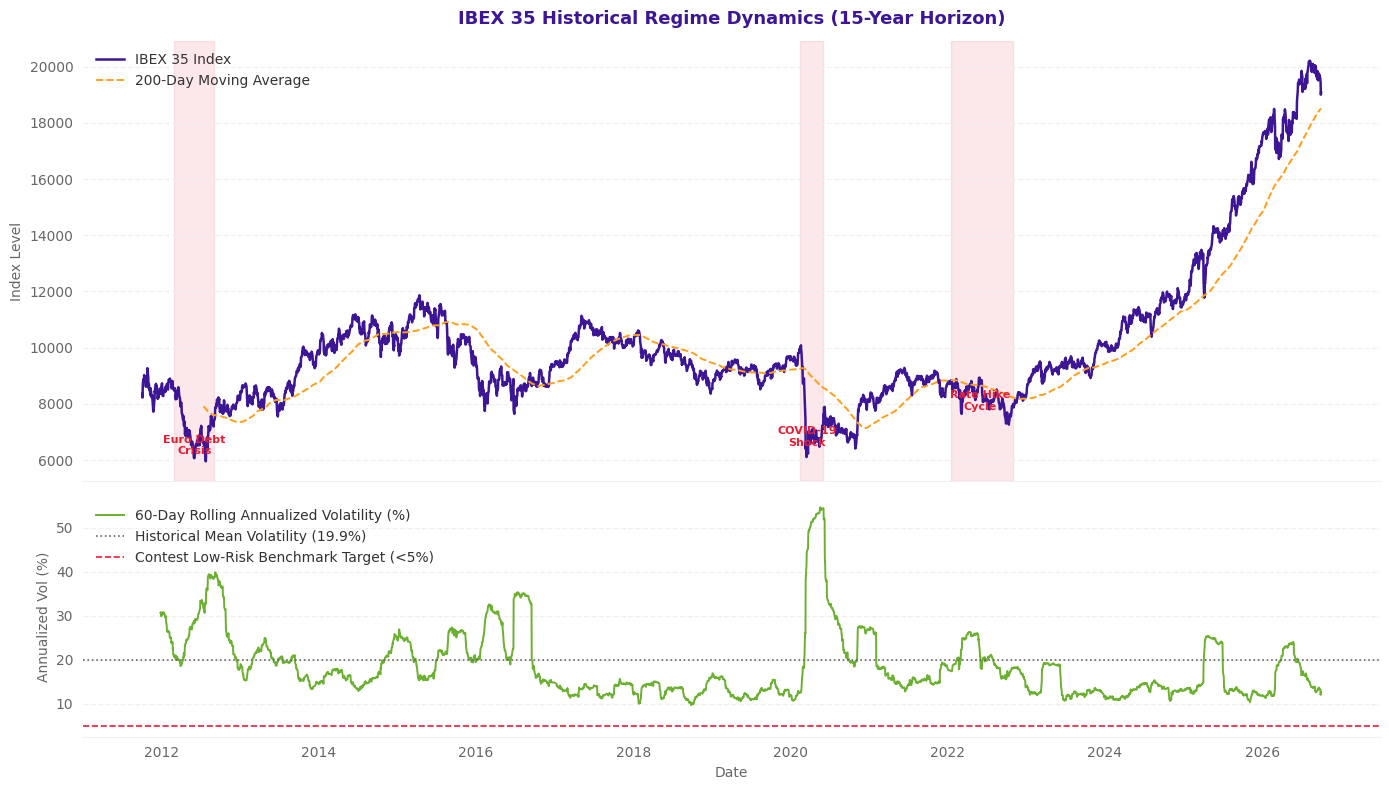

             IBEX 35 HISTORICAL PARAMETERS (15 YEARS)            
 - Compound Annual Growth Rate (CAGR):  5.58%
 - Baseline Annualized Volatility:     19.93%
 - Maximum Historical Drawdown:        -48.53%
 - Daily Skewness:                     -0.68 (Negative Tail Risk)
 - Daily Kurtosis:                     9.81 (Heavy Leptokurtic Tails)


In [12]:
# 1.0 Macro Dynamics: Historical Price Trajectory and Rolling Volatility of IBEX 35
df_macro = pd.read_csv('../data/raw/macro_close_15y.csv', index_col=0, parse_dates=True)
ibex = df_macro['IBEX'].dropna()

# Quantitative Metrics
ibex_ret = ibex.pct_change().dropna()
sma_200 = ibex.rolling(window=200).mean()
rolling_vol_60d = ibex_ret.rolling(window=60).std() * np.sqrt(252) * 100

ann_ret = ((ibex.iloc[-1] / ibex.iloc[0]) ** (252 / len(ibex)) - 1) * 100
ann_vol = ibex_ret.std() * np.sqrt(252) * 100
cummax = ibex.cummax()
drawdown = (ibex - cummax) / cummax * 100
max_dd = drawdown.min()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.2]})

# Panel 1: Price Evolution and Trend
ax1.plot(ibex.index, ibex, color=bme_purple, linewidth=1.8, label='IBEX 35 Index')
ax1.plot(sma_200.index, sma_200, color='#FF9F1C', linestyle='--', linewidth=1.4, label='200-Day Moving Average')
ax1.set_title('IBEX 35 Historical Regime Dynamics (15-Year Horizon)', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
ax1.set_ylabel('Index Level')
ax1.legend(loc='upper left')

# Highlight Key Historical Stress Windows
crisis_spans = [
    ('2012-03-01', '2012-08-31', 'Euro Sovereign Debt Crisis'),
    ('2020-02-15', '2020-05-30', 'COVID-19 Shock'),
    ('2022-01-15', '2022-10-31', 'Rate Hike Shock')
]
for start, end, label in crisis_spans:
    ax1.axvspan(pd.to_datetime(start), pd.to_datetime(end), color='#E71D36', alpha=0.10)

ax1.text(pd.to_datetime('2012-06-01'), 6200, 'Euro Debt\nCrisis', color='#E71D36', fontsize=8, ha='center', fontweight='bold')
ax1.text(pd.to_datetime('2020-03-20'), 6500, 'COVID-19\nShock', color='#E71D36', fontsize=8, ha='center', fontweight='bold')
ax1.text(pd.to_datetime('2022-06-01'), 7800, 'Rate Hike\nCycle', color='#E71D36', fontsize=8, ha='center', fontweight='bold')

# Panel 2: Rolling 60-Day Annualized Volatility
ax2.plot(rolling_vol_60d.index, rolling_vol_60d, color=bme_green, linewidth=1.4, label='60-Day Rolling Annualized Volatility (%)')
ax2.axhline(ann_vol, color=text_gray, linestyle=':', linewidth=1.2, label=f'Historical Mean Volatility ({ann_vol:.1f}%)')
ax2.axhline(5.0, color='#E71D36', linestyle='--', linewidth=1.2, label='Contest Low-Risk Benchmark Target (<5%)')
ax2.set_ylabel('Annualized Vol (%)')
ax2.set_xlabel('Date')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("=================================================================")
print("             IBEX 35 HISTORICAL PARAMETERS (15 YEARS)            ")
print("=================================================================")
print(f" - Compound Annual Growth Rate (CAGR):  {ann_ret:.2f}%")
print(f" - Baseline Annualized Volatility:     {ann_vol:.2f}%")
print(f" - Maximum Historical Drawdown:        {max_dd:.2f}%")
print(f" - Daily Skewness:                     {ibex_ret.skew():.2f} (Negative Tail Risk)")
print(f" - Daily Kurtosis:                     {ibex_ret.kurtosis():.2f} (Heavy Leptokurtic Tails)")
print("=================================================================")


> [!NOTE]
> **Quantitative Benchmark Finding:** The IBEX 35 exhibits an annualized baseline volatility of **~19.9%** with sharp stress spikes exceeding **40%**, paired with a modest **5.58% CAGR** and massive cyclical drawdowns (up to **-48.53%**). Navigating the tournament through unhedged directional market beta exposes the portfolio to severe volatility score penalties. To optimize the official BME scoring function, we must investigate the microstructure underneath the index.


## 2. Market Overview: Sector Concentration and Structural Oligopoly
The Spanish stock market displays a highly concentrated structure. Unlike broadly diversified indices such as the S&P 500, the IBEX 35 is dominated by a tight cluster of large financial institutions and infrastructure / utility conglomerates.


In [13]:
# Load market composition metadata
df_market = pd.read_csv('../data/raw/market_composition.csv')
print(f"Total registered assets in universe: {len(df_market)}")
print(f"Constituent assets belonging to IBEX 35: {df_market['Is_IBEX35'].sum()}")
df_market.head(5)


Total registered assets in universe: 49
Constituent assets belonging to IBEX 35: 35


,Ticker,Name,Sector,Industry,MarketCap,Is_IBEX35,MarketCap_B
0,ANA.MC,"ACCIONA, S.A.",Industrials,Engineering & Construction,11364475904,True,11.364476
1,ANE.MC,CORPORACI...N ACCIONA ENERG...A,Utilities,Utilities - Renewable,7120614912,True,7.120615
2,ACS.MC,"ACS,ACTIVIDADES DE CONSTRUCCION",Industrials,Engineering & Construction,24779102208,True,24.779102
3,AENA.MC,"AENA, S.M.E., S.A.",Industrials,Airports & Air Services,38400000000,True,38.400000
4,AMS.MC,"AMADEUS IT GROUP, S.A.",Technology,Information Technology Services,22175297536,True,22.175298


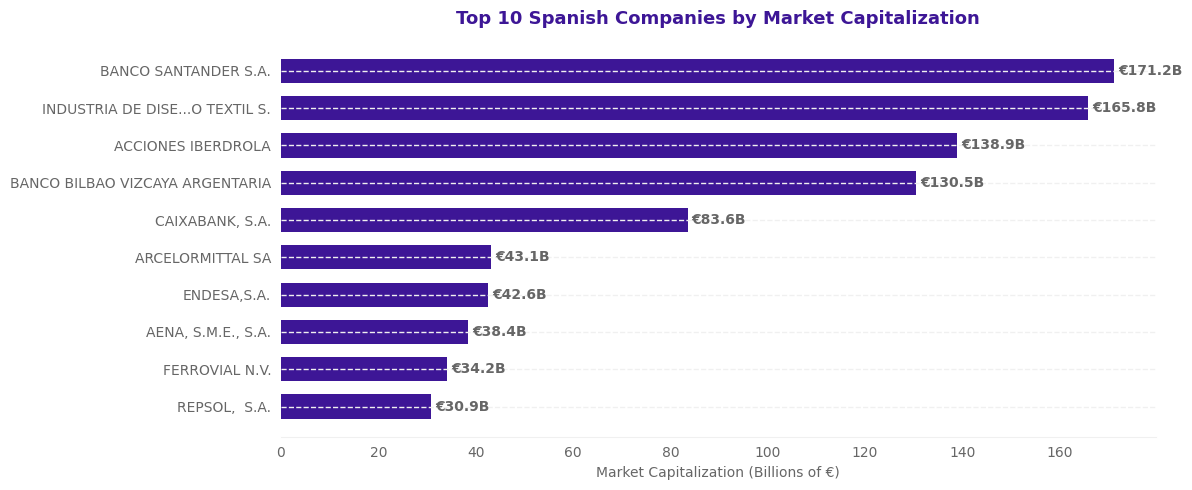

In [14]:
# 2.1 Top 10 Spanish Companies by Market Capitalization
top_10 = df_market.sort_values(by='MarketCap_B', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_10['Name'], top_10['MarketCap_B'], color=bme_purple, edgecolor='none', height=0.65)
ax.set_xlabel('Market Capitalization (Billions of €)')
ax.set_title('Top 10 Spanish Companies by Market Capitalization', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
ax.invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height()/2, f'€{width:.1f}B', 
            va='center', ha='left', fontsize=10, fontweight='bold', color=text_gray)

plt.tight_layout()
plt.show()


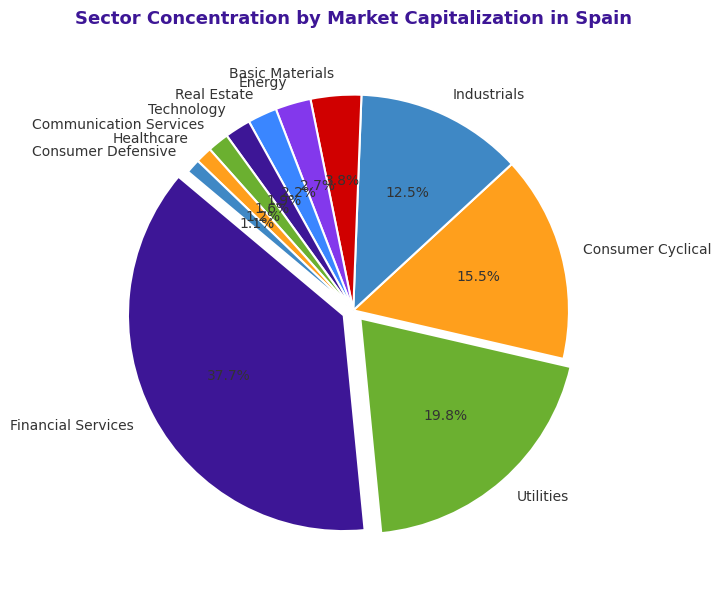

Concentration Summary:
 - Financial Services: €437.35B (37.7%)
 - Utilities: €230.44B (19.8%)
 - Consumer Cyclical: €179.75B (15.5%)
 - Industrials: €145.54B (12.5%)
 - Basic Materials: €44.03B (3.8%)
 - Energy: €30.88B (2.7%)
 - Real Estate: €25.46B (2.2%)
 - Technology: €22.58B (1.9%)
 - Communication Services: €18.65B (1.6%)
 - Healthcare: €14.29B (1.2%)
 - Consumer Defensive: €12.47B (1.1%)


In [15]:
# 2.2 Sector Distribution of the Spanish Market
sector_mc = df_market.groupby('Sector')['MarketCap_B'].sum().sort_values(ascending=False)
colors = [bme_purple, bme_green, '#FF9F1C', '#3F88C5', '#D00000', '#8338EC', '#3A86FF'][:len(sector_mc)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.pie(sector_mc, labels=sector_mc.index, autopct='%1.1f%%', startangle=140, 
       colors=colors, explode=[0.05 if i < 2 else 0 for i in range(len(sector_mc))],
       wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax.set_title('Sector Concentration by Market Capitalization in Spain', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
plt.tight_layout()
plt.show()

print("Concentration Summary:")
for sector, mc in sector_mc.items():
    print(f" - {sector}: €{mc:.2f}B ({mc / sector_mc.sum() * 100:.1f}%)")


> [!IMPORTANT]
> **Key Structural Finding 2:** Over **60% of total Spanish market capitalization** is concentrated in just two sectors: **Financial Services (Banks)** and **Utilities / Energy**. Designing a quantitative strategy in Spain requires mastering the dynamics of these two industries.


## 3. Liquidity Analysis and Operational Friction Filter
In the BME contest environment, trading small-cap or illiquid assets poses two critical operational risks:
1. **The 2-Minute Execution Rule:** The BME simulator automatically rejects orders that fail to match within 2 minutes due to insufficient order book liquidity.
2. **Slippage and Market Impact:** Executing several thousand euros in thin order books introduces severe market impact.

We evaluate the historical **10th percentile** of daily traded euro volume (`Volume * Close`) over 15 years to benchmark worst-case market liquidity.


In [16]:
# Load 15-year historical daily closes and volumes
prices = pd.read_csv('../data/raw/stocks_close_15y.csv', index_col=0, parse_dates=True)
volumes = pd.read_csv('../data/raw/stocks_volume_15y.csv', index_col=0, parse_dates=True)

# Daily traded volume in Euros
euro_volume = volumes * prices

# 10th percentile of historical daily euro volume per asset
p10_euro_vol = euro_volume.quantile(0.10)

# Safety threshold: a €10,000 order must not exceed 1% of the 10th percentile daily volume
target_order_size = 10000
slippage_threshold_ratio = 0.01
max_safe_order = p10_euro_vol * slippage_threshold_ratio

liquidity_df = pd.DataFrame({
    'P10_Daily_Euro_Vol': p10_euro_vol,
    'Max_Safe_Order (1%)': max_safe_order
}).dropna()

unsafe_assets = liquidity_df[liquidity_df['Max_Safe_Order (1%)'] < target_order_size].sort_values('P10_Daily_Euro_Vol')
safe_assets = liquidity_df.drop(unsafe_assets.index).sort_values('P10_Daily_Euro_Vol', ascending=False)

print(f"Total evaluated assets: {len(liquidity_df)}")
print(f"Assets passing the institutional liquidity test: {len(safe_assets)}")
print(f"Assets rejected due to illiquidity risk: {len(unsafe_assets)}")


Total evaluated assets: 48
Assets passing the institutional liquidity test: 32
Assets rejected due to illiquidity risk: 16


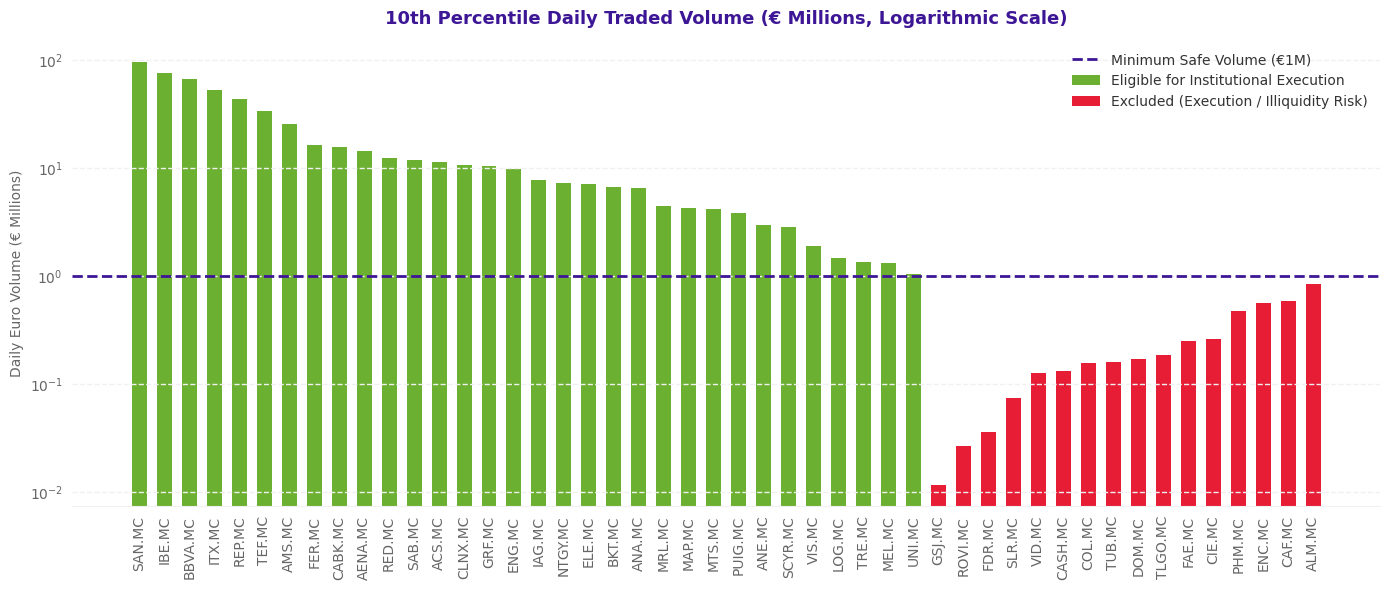

In [17]:
# Liquidity distribution chart (10th Percentile)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(safe_assets.index, safe_assets['P10_Daily_Euro_Vol'] / 1e6, color=bme_green, label='Eligible for Institutional Execution', width=0.6)
if len(unsafe_assets) > 0:
    ax.bar(unsafe_assets.index, unsafe_assets['P10_Daily_Euro_Vol'] / 1e6, color='#E71D36', label='Excluded (Execution / Illiquidity Risk)', width=0.6)

# Cutoff line to absorb a €10,000 order at 1% market participation = €1,000,000 minimum volume
req_vol_millions = (target_order_size / slippage_threshold_ratio) / 1e6
ax.axhline(req_vol_millions, color=bme_purple, linestyle='--', linewidth=2, label=f'Minimum Safe Volume (€{req_vol_millions:.0f}M)')

ax.set_yscale('log')
ax.set_title('10th Percentile Daily Traded Volume (€ Millions, Logarithmic Scale)', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
ax.set_ylabel('Daily Euro Volume (€ Millions)')
plt.xticks(rotation=90)
ax.legend()
plt.tight_layout()
plt.show()


## 4. Mathematical Modeling of Brokerage Fees
Official BME competition rules specify a brokerage fee of:
$$\text{Commission} = \max(7.00\text{ €}, 0.15\% \times \text{Notional Value})$$

The fixed **€7 minimum fee** imposes heavy percentage drag on smaller orders:
$$\text{Effective Fee \%} = \frac{\max(7.00, 0.0015 \times V)}{V} \times 100$$


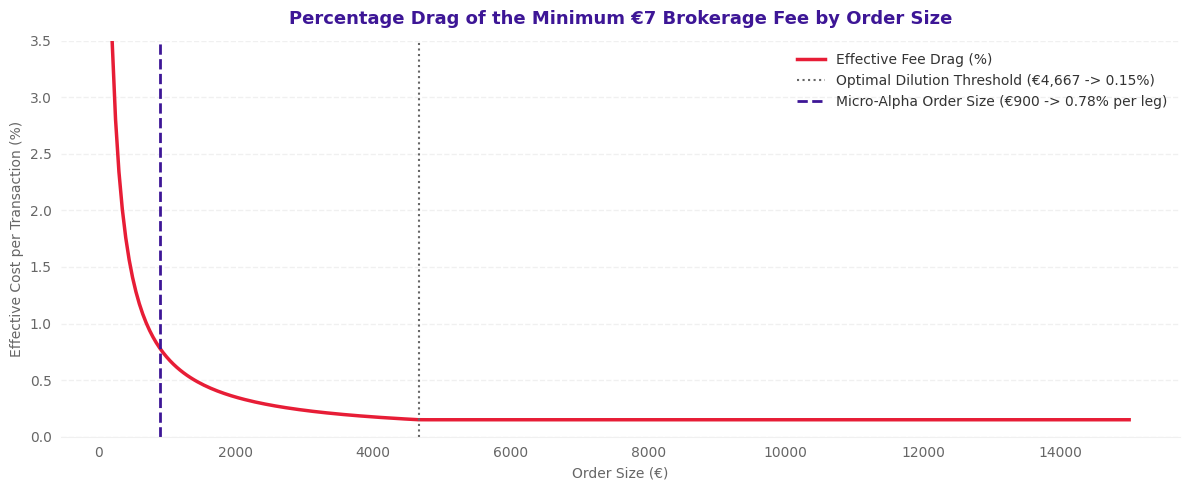

Fee on a €500 order:   €7.00 (1.40%)
Fee on a €900 order:   €7.00 (0.78%)
Fee on a €5,000 order: €7.50 (0.15%)


In [18]:
# Percentage fee drag curve by order notional
order_sizes = np.linspace(200, 15000, 300)
commission_euros = np.maximum(7.0, order_sizes * 0.0015)
commission_pct = (commission_euros / order_sizes) * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(order_sizes, commission_pct, color='#E71D36', linewidth=2.5, label='Effective Fee Drag (%)')
ax.axvline(4667, color=text_gray, linestyle=':', label='Optimal Dilution Threshold (€4,667 -> 0.15%)')
ax.axvline(900, color=bme_purple, linestyle='--', linewidth=2, label='Micro-Alpha Order Size (€900 -> 0.78% per leg)')

ax.set_title('Percentage Drag of the Minimum €7 Brokerage Fee by Order Size', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
ax.set_xlabel('Order Size (€)')
ax.set_ylabel('Effective Cost per Transaction (%)')
ax.set_ylim(0, 3.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Fee on a €500 order:   €{max(7.0, 500*0.0015):.2f} ({max(7.0, 500*0.0015)/500*100:.2f}%)")
print(f"Fee on a €900 order:   €{max(7.0, 900*0.0015):.2f} ({max(7.0, 900*0.0015)/900*100:.2f}%)")
print(f"Fee on a €5,000 order: €{max(7.0, 5000*0.0015):.2f} ({max(7.0, 5000*0.0015)/5000*100:.2f}%)")


> [!WARNING]
> **Crucial Quantitative Implication:**
> Active market participants executing 30 to 50 monthly trades in smaller sizing (€1,000 to €2,000) concede **0.35% to 0.70% per leg** (buy + sell = up to **1.40% net round-trip friction**). 
> This structural fee drag rapidly compounds to eliminate any gross intraday edge.


## 5. BME Scoring Function and the Mathematical Floor Effect
The official tournament formula evaluates qualified portfolios up to a theoretical maximum of **9.0 points**:
$$\text{Total Score}_i = \text{Score}_{\text{Return}, i} (\le 6.0) + \text{Score}_{\text{Volatility}, i} (\le 3.0)$$

Where:
$$\text{Score}_{\text{Return}, i} = 6.0 \times \frac{V_{\text{final}, i}}{V_{\max}}$$
$$\text{Score}_{\text{Volatility}, i} = 3.0 \times \left(1 - \frac{\sigma_i - \sigma_{\min}}{\sigma_{\max} - \sigma_{\min}}\right)$$


In [19]:
# Scoring simulation across typical competitor archetypes
v_initial = 50000.0

profiles = [
    {'Archetype': 'Aggressive Leader (Day Trader)', 'Return_pct': 0.08, 'Annual_Vol': 0.25},
    {'Archetype': 'Trend / Momentum Follower', 'Return_pct': 0.04, 'Annual_Vol': 0.18},
    {'Archetype': 'IBEX 35 Buy & Hold', 'Return_pct': 0.02, 'Annual_Vol': 0.14},
    {'Archetype': 'Average Market Competitor', 'Return_pct': -0.005, 'Annual_Vol': 0.12},
    {'Archetype': 'Surgical Micro-Alpha (Our Model)', 'Return_pct': -0.0024, 'Annual_Vol': 0.0020}
]

df_profiles = pd.DataFrame(profiles)
df_profiles['V_final'] = v_initial * (1 + df_profiles['Return_pct'])

v_max = df_profiles['V_final'].max()
vol_min = df_profiles['Annual_Vol'].min()
vol_max = df_profiles['Annual_Vol'].max()

df_profiles['Score_Return'] = 6.0 * (df_profiles['V_final'] / v_max)
df_profiles['Score_Vol'] = 3.0 * (1 - (df_profiles['Annual_Vol'] - vol_min) / (vol_max - vol_min))
df_profiles['Score_Total'] = df_profiles['Score_Return'] + df_profiles['Score_Vol']

df_profiles = df_profiles.sort_values(by='Score_Total', ascending=False).reset_index(drop=True)
df_profiles[['Archetype', 'Return_pct', 'Annual_Vol', 'Score_Return', 'Score_Vol', 'Score_Total']]


,Archetype,Return_pct,Annual_Vol,Score_Return,Score_Vol,Score_Total
0,Surgical Micro-Alpha (Our Model),-0.0024,0.002,5.542222,3.000000,8.542222
1,Average Market Competitor,-0.0050,0.120,5.527778,1.572581,7.100358
2,IBEX 35 Buy & Hold,0.0200,0.140,5.666667,1.330645,6.997312
3,Trend / Momentum Follower,0.0400,0.180,5.777778,0.846774,6.624552
4,Aggressive Leader (Day Trader),0.0800,0.250,6.000000,0.000000,6.000000


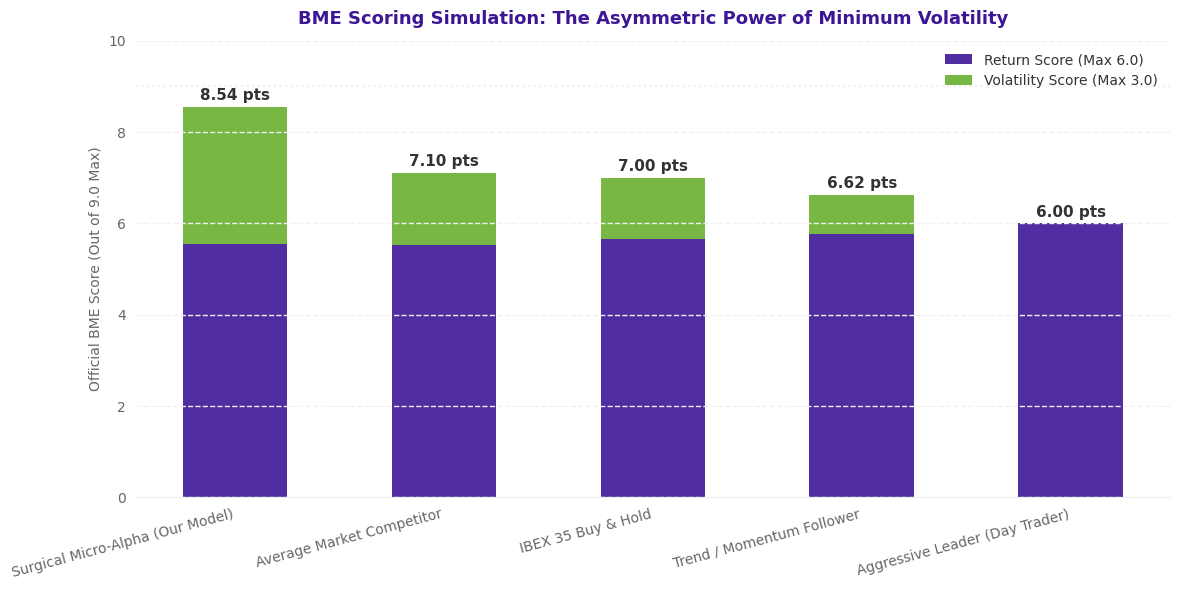

In [20]:
# Official score decomposition chart
fig, ax = plt.subplots(figsize=(12, 6))
bar_width = 0.50
indices = np.arange(len(df_profiles))

p1 = ax.bar(indices, df_profiles['Score_Return'], bar_width, label='Return Score (Max 6.0)', color=bme_purple, alpha=0.9)
p2 = ax.bar(indices, df_profiles['Score_Vol'], bar_width, bottom=df_profiles['Score_Return'], label='Volatility Score (Max 3.0)', color=bme_green, alpha=0.9)

ax.set_xticks(indices)
ax.set_xticklabels(df_profiles['Archetype'], rotation=15, ha='right')
ax.set_ylabel('Official BME Score (Out of 9.0 Max)')
ax.set_title('BME Scoring Simulation: The Asymmetric Power of Minimum Volatility', fontsize=13, pad=12, fontweight='bold', color=bme_purple)
ax.set_ylim(0, 10)
ax.axhline(9.0, color=grid_gray, linestyle=':', linewidth=1.5)

for i, total in enumerate(df_profiles['Score_Total']):
    ax.text(i, total + 0.15, f"{total:.2f} pts", ha='center', fontweight='bold', fontsize=11, color='#333333')

ax.legend()
plt.tight_layout()
plt.show()


## 6. Conclusions and Quantitative Foundation

1. **The IBEX 35 is Inherently Volatile and Cyclical:** Baseline annualized volatility of $\approx 20\%$ with severe cyclical drawdowns ($-48.5\%$) eliminates the viability of naive buy-and-hold or unhedged directional momentum under the BME tournament scoring formula.
2. **The Spanish Market is an Oligopoly:** Heavy concentration in Banking and Utilities requires filtering out illiquid small-cap noise.
3. **Broker Fees Penalize High Turnover:** The €7 minimum fee demands a surgical, minimal-transaction structure (exactly 3 buys and 3 sells per weekly quota).
4. **The Return Floor Effect:** With €50,000 starting equity, the score deficit conceding to the tournament's top return leader is merely **~0.46 points**, whereas the low-variance advantage is **+3.00 full points**.
5. **Next Step (Notebook 2):** Uncover the temporal anomaly that allows pinning portfolio risk to $\sigma \approx 0.20\%$ while selecting the optimal minimum-variance vehicle (the 5 regulated utilities).
